In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
    ("xgboost",   "xgboost==2.0.3",        "xgboost==2.0.3"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B4 — Phát Hiện Tấn Công Web bằng Học Máy (ML)


## 1. Import & Cấu Hình

In [1]:
# ─── Thư viện chuẩn ────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, time
from pathlib import Path
warnings.filterwarnings('ignore')

# ─── Sklearn: tiền xử lý ───────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

# ─── Sklearn: mô hình ──────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# ─── XGBoost ───────────────────────────────────────────────────────────────────
from xgboost import XGBClassifier

# ─── Sklearn: đánh giá ─────────────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay
)

# ─── Cấu hình ──────────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 42

root_folder = Path.cwd()
DATA_PATH = (
    root_folder.parent / "Dataset" / "capec_small_multilabel2.csv"
)  # Điều chỉnh đường dẫn nếu cần

print('✅ Import thành công!')
import sklearn; print(f'   scikit-learn: {sklearn.__version__}')
import xgboost; print(f'   xgboost     : {xgboost.__version__}')

✅ Import thành công!
   scikit-learn: 1.2.0
   xgboost     : 2.0.3


## 2. Tải & Tiền Xử Lý Dữ Liệu

In [2]:
# ──────────────────────────────────────────────────────────────────────────────
# 📥 TẢI DỮ LIỆU
# ──────────────────────────────────────────────────────────────────────────────

# Thông báo bắt đầu quá trình load dataset
print("⏳ Đang tải dữ liệu...")

# Đọc file CSV vào DataFrame
# low_memory=False giúp tránh lỗi suy luận dtype khi dữ liệu lớn/không đồng nhất
df = pd.read_csv(DATA_PATH, low_memory=False)

# In kích thước dữ liệu: (số dòng, số cột)
print(f"✅ Đã tải: {df.shape[0]:,} rows × {df.shape[1]} cols")


# ──────────────────────────────────────────────────────────────────────────────
# 🏷️ XÁC ĐỊNH CÁC NHÓM CỘT NHÃN
# ──────────────────────────────────────────────────────────────────────────────

# LABEL_COLS:
# Các cột nhãn CAPEC được nhận diện dựa trên pattern " - "
# Ví dụ: "126 - Path Traversal"
LABEL_COLS = [c for c in df.columns if " - " in c]

# ATTACK_COLS:
# Loại bỏ nhãn "000 - Normal" để chỉ giữ các loại tấn công
# → dùng khi muốn phân tích riêng malicious samples
ATTACK_COLS = [c for c in LABEL_COLS if c != "000 - Normal"]


# ──────────────────────────────────────────────────────────────────────────────
# 🧠 CHUẨN HÓA TÊN NHÃN
# ──────────────────────────────────────────────────────────────────────────────

# ATTACK_NAMES:
# Mapping từ full label → tên ngắn gọn (bỏ mã CAPEC)
# Ví dụ:
# "126 - Path Traversal" → "Path Traversal"
ATTACK_NAMES = {c: c.split(" - ")[1] for c in LABEL_COLS}


# ──────────────────────────────────────────────────────────────────────────────
# 📊 THỐNG KÊ PHÂN BỐ NHÃN
# ──────────────────────────────────────────────────────────────────────────────

print(f"\n🏷️  Các nhãn CAPEC ({len(LABEL_COLS)}):")

# Với mỗi nhãn CAPEC:
# df[c].sum() = tổng số sample thuộc nhãn đó (vì one-hot encoding 0/1)
for c in LABEL_COLS:
    print(f"   {c}: {df[c].sum():,}")

⏳ Đang tải dữ liệu...
✅ Đã tải: 10,000 rows × 38 cols

🏷️  Các nhãn CAPEC (14):
   000 - Normal: 5,000
   272 - Protocol Manipulation: 672
   242 - Code Injection: 584
   88 - OS Command Injection: 622
   126 - Path Traversal: 766
   66 - SQL Injection: 723
   16 - Dictionary-based Password Attack: 61
   310 - Scanning for Vulnerable Software: 514
   153 - Input Data Manipulation: 504
   248 - Command Injection: 0
   274 - HTTP Verb Tampering: 582
   194 - Fake the Source of Data: 500
   34 - HTTP Response Splitting: 503
   33 - HTTP Request Smuggling: 62


In [3]:
# ═══════════════════════════════════════════════════════════════════════════════
# FEATURE ENGINEERING
# Trích xuất các đặc trưng có ý nghĩa từ HTTP log thô
# ═══════════════════════════════════════════════════════════════════════════════

def extract_features(df: pd.DataFrame) -> pd.DataFrame:
    """Trích xuất đặc trưng từ raw HTTP log.

    Nhóm 1 — URL features:
        Payload tấn công thường nằm trong URL, tạo các dấu hiệu đặc trưng
        như URL dài, ký tự đặc biệt, URL encoding.

    Nhóm 2 — HTTP header features:
        HTTP method bất thường (TRACE, TRACK) → Protocol Manipulation
        Header vắng mặt → automation/script attack

    Nhóm 3 — Response features:
        Status code cao (4xx/5xx) → server phát hiện bất thường
        Content length nhỏ → lỗi, không có nội dung thực
    """
    feat = pd.DataFrame(index=df.index)

    # ── Nhóm 1: URL features ──────────────────────────────────────────────────
    url = df['request_http_request'].astype(str).str.lower()
    feat['url_length']         = url.str.len()
    feat['url_depth']          = url.str.count(r'/').clip(0, 20)  # Số cấp path
    feat['url_has_query']      = url.str.contains(r'\?').astype(int)
    feat['url_query_len']      = url.apply(lambda x: len(x.split('?')[1]) if '?' in x else 0)
    feat['url_special_chars']  = url.str.count(r"[<>'\"%;()&+]")    # Ký tự SQL/XSS
    feat['url_encoded_chars']  = url.str.count(r'%[0-9a-f]{2}')     # URL encoding
    feat['url_double_encoded'] = url.str.count(r'%25[0-9a-f]{2}')   # Double encoding
    feat['url_has_dotdot']     = url.str.contains(r'\.\.').astype(int)  # Path traversal
    feat['url_has_semicolon']  = url.str.contains(r';').astype(int)  # SQL/cmd injection
    feat['url_has_union']      = url.str.contains('union').astype(int)  # SQL UNION
    feat['url_has_select']     = url.str.contains('select').astype(int)  # SQL SELECT
    feat['url_has_exec']       = url.str.contains(r'exec|eval|system|passthru').astype(int)
    feat['url_num_params']     = url.str.count(r'[&=]')  # Số param trong query string

    # ── Nhóm 2: HTTP Header features ─────────────────────────────────────────
    method = df['request_http_method'].astype(str).str.upper()
    NORMAL_METHODS = {'GET', 'POST', 'HEAD', 'OPTIONS', 'PUT', 'DELETE', 'PATCH'}
    feat['method_is_get']     = (method == 'GET').astype(int)
    feat['method_is_post']    = (method == 'POST').astype(int)
    feat['method_is_unusual'] = (~method.isin(NORMAL_METHODS)).astype(int)  # TRACE, TRACK...
    feat['has_user_agent']    = df['request_user_agent'].notna().astype(int)
    feat['has_referer']       = df['request_referer'].notna().astype(int)
    feat['has_cookie']        = df['request_cookie'].notna().astype(int)
    feat['has_content_type']  = df['request_content_type'].notna().astype(int)
    feat['has_body']          = df['request_body'].notna().astype(int)

    # User-agent đặc trưng: bot/scanner không dùng browser thật
    ua = df['request_user_agent'].fillna('').astype(str).str.lower()
    feat['ua_length']         = ua.str.len()
    feat['ua_has_mozilla']    = ua.str.contains('mozilla').astype(int)
    feat['ua_has_curl_wget']  = ua.str.contains(r'curl|wget|python|nikto|sqlmap').astype(int)

    # ── Nhóm 3: Response features ────────────────────────────────────────────
    feat['status_code']        = pd.to_numeric(df['response_http_status_code'], errors='coerce').fillna(0)
    feat['content_length']     = pd.to_numeric(df['response_content_length'],   errors='coerce').fillna(0)
    feat['status_is_4xx']      = ((feat['status_code'] >= 400) & (feat['status_code'] < 500)).astype(int)
    feat['status_is_5xx']      = (feat['status_code'] >= 500).astype(int)
    feat['status_is_200']      = (feat['status_code'] == 200).astype(int)
    feat['log_content_length'] = np.log1p(feat['content_length'])  # Log transform để giảm skew

    # ── Nhóm 4: Port features ────────────────────────────────────────────────
    feat['src_port']  = pd.to_numeric(df['src_port'], errors='coerce').fillna(0).astype(int)
    feat['dst_port']  = pd.to_numeric(df['dst_port'], errors='coerce').fillna(80).astype(int)

    return feat.fillna(0)


print('⏳ Đang trích xuất đặc trưng...')
X = extract_features(df)
print(f'✅ Feature matrix: {X.shape[0]:,} × {X.shape[1]} (đặc trưng: {X.columns.tolist()})')

⏳ Đang trích xuất đặc trưng...
✅ Feature matrix: 10,000 × 32 (đặc trưng: ['url_length', 'url_depth', 'url_has_query', 'url_query_len', 'url_special_chars', 'url_encoded_chars', 'url_double_encoded', 'url_has_dotdot', 'url_has_semicolon', 'url_has_union', 'url_has_select', 'url_has_exec', 'url_num_params', 'method_is_get', 'method_is_post', 'method_is_unusual', 'has_user_agent', 'has_referer', 'has_cookie', 'has_content_type', 'has_body', 'ua_length', 'ua_has_mozilla', 'ua_has_curl_wget', 'status_code', 'content_length', 'status_is_4xx', 'status_is_5xx', 'status_is_200', 'log_content_length', 'src_port', 'dst_port'])


In [4]:
# ═══════════════════════════════════════════════════════════════════════════════
# TẠO NHÃN CHO 2 BÀI TOÁN
# ═══════════════════════════════════════════════════════════════════════════════

# ── Bài toán 1: Binary Classification ───────────────────────────────────────
# y_binary = 0 nếu là Normal, 1 nếu có bất kỳ loại tấn công nào
y_binary = (df['000 - Normal'] == 0).astype(int)
print(f'📊 Binary labels:')
print(f'   Normal (0): {(y_binary==0).sum():>10,}  ({(y_binary==0).mean()*100:.1f}%)')
print(f'   Attack (1): {(y_binary==1).sum():>10,}  ({(y_binary==1).mean()*100:.1f}%)')

# ── Bài toán 2: Multiclass Classification ───────────────────────────────────
# Dataset là multilabel → chuyển về single-label bằng cách chọn nhãn ưu tiên:
#   Normal (0) nếu tất cả attack_cols = 0
#   Loại tấn công có chỉ số thấp nhất nếu nhiều nhãn cùng = 1
#   (CAPEC mã nhỏ hơn thường là loại tổng quát hơn)
label_priority = LABEL_COLS  # Thứ tự ưu tiên: Normal trước

def get_primary_label(row):
    """Trả về nhãn đầu tiên có giá trị = 1 theo thứ tự ưu tiên."""
    for col in label_priority:
        if row[col] == 1:
            return col
    return '000 - Normal'  # Fallback

print('\n⏳ Đang tạo nhãn multiclass...')
y_multi_str = df[LABEL_COLS].apply(get_primary_label, axis=1)

# Encode nhãn chuỗi → số nguyên
le = LabelEncoder()
y_multi = le.fit_transform(y_multi_str)

print(f'✅ Multiclass labels ({len(le.classes_)} lớp):')
for i, cls in enumerate(le.classes_):
    count = (y_multi == i).sum()
    bar = '█' * int(count / len(y_multi) * 40)
    print(f'   [{i:2d}] {cls.split(" - ")[1][:35]:<35}: {count:>7,}  {bar}')

📊 Binary labels:
   Normal (0):      5,000  (50.0%)
   Attack (1):      5,000  (50.0%)

⏳ Đang tạo nhãn multiclass...
✅ Multiclass labels (12 lớp):
   [ 0] Normal                             :   5,000  ████████████████████
   [ 1] Path Traversal                     :     455  █
   [ 2] Input Data Manipulation            :     293  █
   [ 3] Dictionary-based Password Attack   :      27  
   [ 4] Fake the Source of Data            :     499  █
   [ 5] Code Injection                     :     582  ██
   [ 6] Protocol Manipulation              :     672  ██
   [ 7] HTTP Verb Tampering                :     391  █
   [ 8] Scanning for Vulnerable Software   :     440  █
   [ 9] HTTP Response Splitting            :     499  █
   [10] SQL Injection                      :     648  ██
   [11] OS Command Injection               :     494  █


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# TRAIN / VALIDATION / TEST SPLIT
# Chiến lược: 70% train | 15% val | 15% test
# Dùng stratify để đảm bảo phân bố nhãn đồng đều
# ═══════════════════════════════════════════════════════════════════════════════

# Bước 1: tách 15% test
X_trainval, X_test, y_bin_trainval, y_bin_test, y_mul_trainval, y_mul_test = \
    train_test_split(X, y_binary, y_multi,
                     test_size=0.15, random_state=RANDOM_STATE, stratify=y_binary)

# Bước 2: tách 15% val từ phần còn lại (= 15% / 85% ≈ 17.6%)
X_train, X_val, y_bin_train, y_bin_val, y_mul_train, y_mul_val = \
    train_test_split(X_trainval, y_bin_trainval, y_mul_trainval,
                     test_size=0.176, random_state=RANDOM_STATE, stratify=y_bin_trainval)

# Chuẩn hóa đặc trưng số (StandardScaler: mean=0, std=1)
# Fit trên train, transform trên val và test để tránh data leakage
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print('📊 Kích thước tập dữ liệu sau khi split:')
print(f'   Train : {X_train.shape[0]:>8,} ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'   Val   : {X_val.shape[0]:>8,} ({X_val.shape[0]/len(X)*100:.1f}%)')
print(f'   Test  : {X_test.shape[0]:>8,} ({X_test.shape[0]/len(X)*100:.1f}%)')
print(f'   Features: {X_train.shape[1]}')

📊 Kích thước tập dữ liệu sau khi split:
   Train :    7,004 (70.0%)
   Val   :    1,496 (15.0%)
   Test  :    1,500 (15.0%)
   Features: 32


## 3. Phân Loại Nhị Phân (Binary Classification)

### 3.1 Huấn Luyện Các Mô Hình

In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# ĐỊNH NGHĨA CÁC MÔ HÌNH PHÂN LOẠI NHỊ PHÂN (BINARY CLASSIFICATION)
# Mục tiêu: so sánh nhiều thuật toán ML trên bài toán Benign vs Attack
# ═══════════════════════════════════════════════════════════════════════════════

binary_models = {
    # --------------------------
    # Decision Tree
    # --------------------------
    # - Mô hình cây quyết định đơn giản
    # - Dễ giải thích, không cần chuẩn hóa dữ liệu
    # - Có thể overfit nếu không giới hạn độ sâu
    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,  # giới hạn độ sâu cây để giảm overfitting
        min_samples_leaf=20,  # mỗi lá phải có ít nhất 20 mẫu
        class_weight="balanced",  # xử lý mất cân bằng lớp
        random_state=RANDOM_STATE,
    ),
    # --------------------------
    # Random Forest
    # --------------------------
    # - Ensemble nhiều Decision Tree
    # - Ổn định hơn, giảm overfitting
    # - Rất mạnh với dữ liệu tabular (network security)
    "Random Forest": RandomForestClassifier(
        n_estimators=100,  # số lượng cây trong rừng
        max_depth=20,  # giới hạn độ sâu mỗi cây
        min_samples_leaf=10,  # giảm overfitting
        class_weight="balanced",  # xử lý imbalance
        n_jobs=-1,  # sử dụng toàn bộ CPU cores
        random_state=RANDOM_STATE,
    ),
    # --------------------------
    # XGBoost
    # --------------------------
    # - Gradient Boosting nâng cao (state-of-the-art cho tabular data)
    # - Hiệu suất cao, xử lý tốt dữ liệu mất cân bằng
    "XGBoost": XGBClassifier(
        n_estimators=200,  # số vòng boosting
        max_depth=8,  # kiểm soát độ phức tạp mô hình
        learning_rate=0.1,  # tốc độ học (shrinkage)
        subsample=0.8,  # lấy mẫu hàng để giảm overfitting
        colsample_bytree=0.8,  # lấy mẫu feature mỗi cây
        # xử lý mất cân bằng lớp (important trong cybersecurity)
        scale_pos_weight=((y_bin_train == 0).sum() / (y_bin_train == 1).sum()),
        tree_method="hist",  # tăng tốc training trên dataset lớn
        n_jobs=-1,  # dùng toàn bộ CPU
        random_state=RANDOM_STATE,
        eval_metric="logloss",  # metric nội bộ cho training
    ),
}

# ═══════════════════════════════════════════════════════════════════════════════
# TRAINING + EVALUATION LOOP
# ═══════════════════════════════════════════════════════════════════════════════

binary_results = {}

for name, model in binary_models.items():

    # Bắt đầu đo thời gian training
    print(f"\n⏳ Training: {name}...")
    t0 = time.time()

    # --------------------------
    # Chọn dữ liệu đầu vào
    # --------------------------
    # Logistic Regression cần dữ liệu đã chuẩn hóa (scaled)
    # Tree-based models không yêu cầu scaling
    X_tr = X_train_s if "Logistic" in name else X_train
    X_vl = X_val_s if "Logistic" in name else X_val

    # --------------------------
    # Huấn luyện mô hình
    # --------------------------
    model.fit(X_tr, y_bin_train)

    # --------------------------
    # Dự đoán nhãn
    # --------------------------
    y_pred = model.predict(X_vl)

    # --------------------------
    # Xác suất dự đoán (dùng cho ROC-AUC)
    # --------------------------
    y_prob = (
        model.predict_proba(X_vl)[:, 1] if hasattr(model, "predict_proba") else None
    )

    # Tính thời gian huấn luyện
    elapsed = time.time() - t0

    # --------------------------
    # Lưu kết quả đánh giá
    # --------------------------
    binary_results[name] = {
        "model": model,
        # Metrics cơ bản
        "acc": accuracy_score(y_bin_val, y_pred),
        "precision": precision_score(y_bin_val, y_pred, zero_division=0),
        "recall": recall_score(y_bin_val, y_pred, zero_division=0),
        "f1": f1_score(y_bin_val, y_pred, zero_division=0),
        # ROC-AUC (chỉ tính khi có probability output)
        "auc": roc_auc_score(y_bin_val, y_prob) if y_prob is not None else 0,
        # lưu prediction để phân tích sau
        "y_pred": y_pred,
        "y_prob": y_prob,
        # thời gian training
        "time": elapsed,
    }

    # --------------------------
    # In kết quả từng model
    # --------------------------
    print(
        f"   ✅ Done ({elapsed:.1f}s) | "
        f'Acc={binary_results[name]["acc"]:.4f} | '
        f'F1={binary_results[name]["f1"]:.4f} | '
        f'AUC={binary_results[name]["auc"]:.4f}'
    )

# Hoàn thành training tất cả mô hình
print("\n✅ Hoàn thành training binary models!")


⏳ Training: Decision Tree...
   ✅ Done (0.0s) | Acc=0.9445 | F1=0.9441 | AUC=0.9911

⏳ Training: Random Forest...
   ✅ Done (0.3s) | Acc=0.9425 | F1=0.9416 | AUC=0.9917

⏳ Training: XGBoost...
   ✅ Done (2.0s) | Acc=0.9572 | F1=0.9570 | AUC=0.9954

✅ Hoàn thành training binary models!


### 3.2 So Sánh Kết Quả Binary

📊 Kết quả so sánh trên Validation Set (Binary Classification):


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Time (s)
Model,,,,,,
Decision Tree,0.9445,0.9512,0.9372,0.9441,0.9911,0.0
Random Forest,0.9425,0.9572,0.9265,0.9416,0.9917,0.3
XGBoost,0.9572,0.9622,0.9519,0.9570,0.9954,2.0


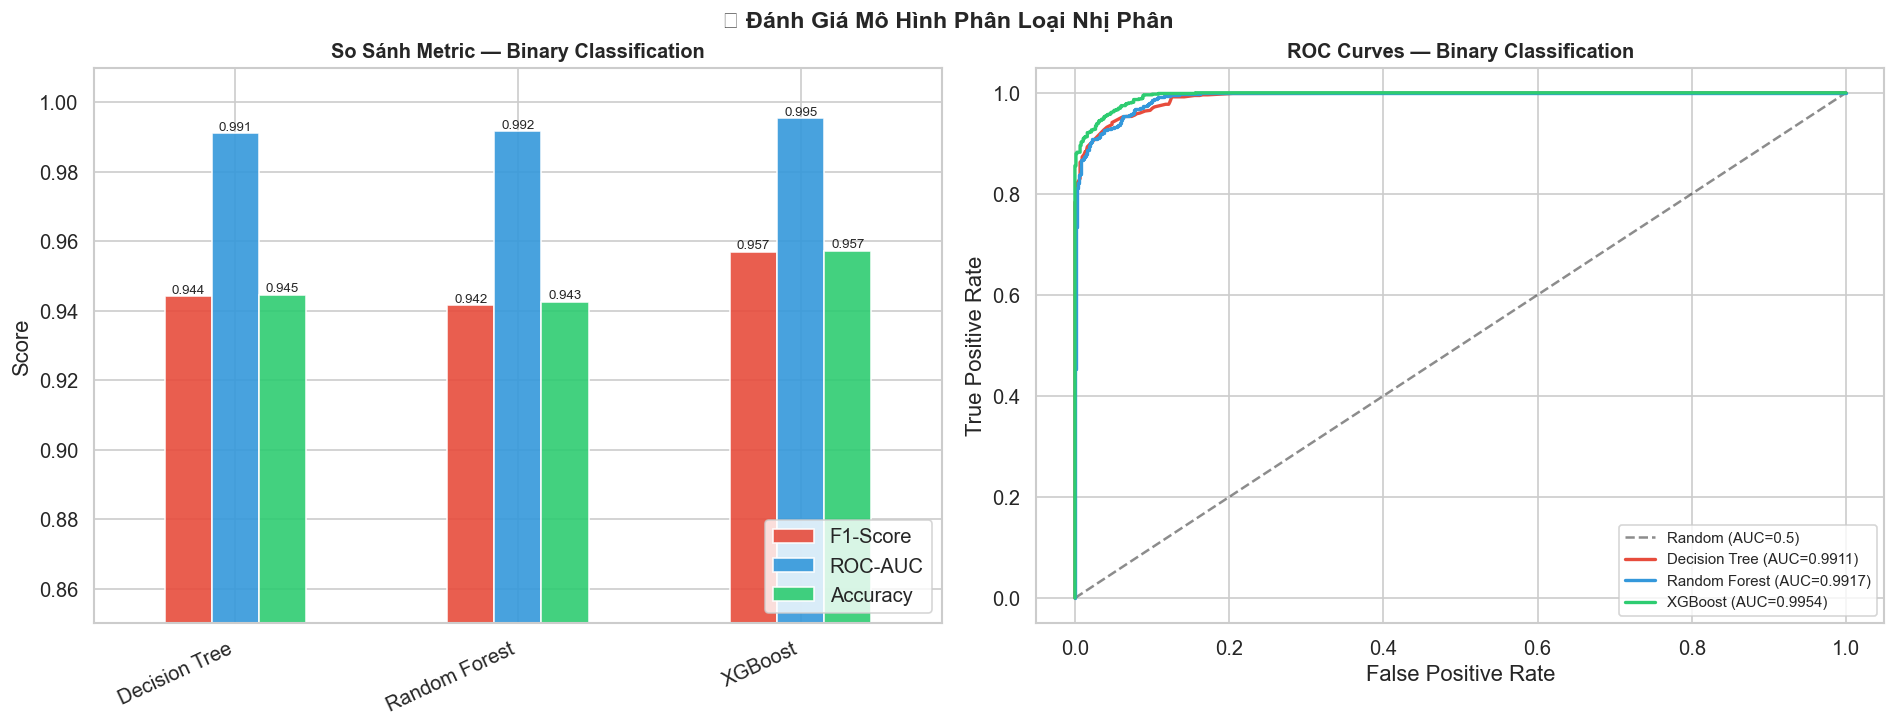

In [7]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📊 TỔNG HỢP KẾT QUẢ MÔ HÌNH (BINARY CLASSIFICATION)
# ═══════════════════════════════════════════════════════════════════════════════

# --------------------------
# Tạo bảng kết quả tổng hợp
# --------------------------
# Mục tiêu:
# - Gom tất cả metric của từng model vào DataFrame
# - Dễ so sánh và xuất báo cáo
results_df = pd.DataFrame(
    [
        {
            "Model": name,
            "Accuracy": f"{v['acc']:.4f}",  # độ chính xác tổng thể
            "Precision": f"{v['precision']:.4f}",  # độ chính xác dự đoán attack
            "Recall": f"{v['recall']:.4f}",  # khả năng phát hiện attack
            "F1-Score": f"{v['f1']:.4f}",  # cân bằng Precision/Recall
            "ROC-AUC": f"{v['auc']:.4f}",  # khả năng phân biệt 2 lớp
            "Time (s)": f"{v['time']:.1f}",  # thời gian huấn luyện
        }
        for name, v in binary_results.items()
    ]
)

# In bảng kết quả
print("📊 Kết quả so sánh trên Validation Set (Binary Classification):")
display(results_df.set_index("Model"))


# ═══════════════════════════════════════════════════════════════════════════════
# 📈 TRỰC QUAN HÓA KẾT QUẢ MÔ HÌNH
# ═══════════════════════════════════════════════════════════════════════════════

# Tạo figure gồm 2 subplot:
# (1) Bar chart so sánh metric
# (2) ROC curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


# ───────────────────────────────────────────────────────────────────────────────
# 📊 1. BAR CHART SO SÁNH METRIC
# ───────────────────────────────────────────────────────────────────────────────

# Gom các metric quan trọng để so sánh giữa các model
metrics_plot = pd.DataFrame(
    {
        "F1-Score": [binary_results[m]["f1"] for m in binary_results],
        "ROC-AUC": [binary_results[m]["auc"] for m in binary_results],
        "Accuracy": [binary_results[m]["acc"] for m in binary_results],
    },
    index=list(binary_results.keys()),
)

# Vẽ bar chart
metrics_plot.plot(
    kind="bar",
    ax=axes[0],
    color=["#e74c3c", "#3498db", "#2ecc71"],  # đỏ, xanh dương, xanh lá
    edgecolor="white",
    alpha=0.9,
)

# Format trục X
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25, ha="right")

# Giới hạn trục Y (vì metric thường nằm gần 1)
axes[0].set_ylim(0.85, 1.01)

# Tiêu đề biểu đồ
axes[0].set_title(
    "So Sánh Metric — Binary Classification", fontsize=12, fontweight="bold"
)

axes[0].set_ylabel("Score")
axes[0].legend(loc="lower right")

# Hiển thị giá trị trên từng cột
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8)


# ───────────────────────────────────────────────────────────────────────────────
# 📈 2. ROC CURVES (Receiver Operating Characteristic)
# ───────────────────────────────────────────────────────────────────────────────

# Đường baseline (random classifier)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random (AUC=0.5)")

# Màu cho từng model
colors_roc = ["#e74c3c", "#3498db", "#2ecc71", "#f39c12"]

# Vẽ ROC curve cho từng model
for (name, v), col in zip(binary_results.items(), colors_roc):

    # chỉ vẽ nếu model có xác suất dự đoán
    if v["y_prob"] is not None:

        # Tính FPR và TPR
        fpr, tpr, _ = roc_curve(y_bin_val, v["y_prob"])

        # Vẽ đường ROC
        axes[1].plot(
            fpr, tpr, color=col, linewidth=2, label=f"{name} (AUC={v['auc']:.4f})"
        )

# Nhãn trục
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")

# Tiêu đề ROC plot
axes[1].set_title("ROC Curves — Binary Classification", fontsize=12, fontweight="bold")

axes[1].legend(fontsize=9)


# ═══════════════════════════════════════════════════════════════════════════════
# 🎯 FINAL FORMATTING
# ═══════════════════════════════════════════════════════════════════════════════

plt.tight_layout()

# Tiêu đề tổng
plt.suptitle(
    "🔬 Đánh Giá Mô Hình Phân Loại Nhị Phân", fontsize=14, fontweight="bold", y=1.01
)

plt.show()

🏆 Mô hình tốt nhất (F1): XGBoost


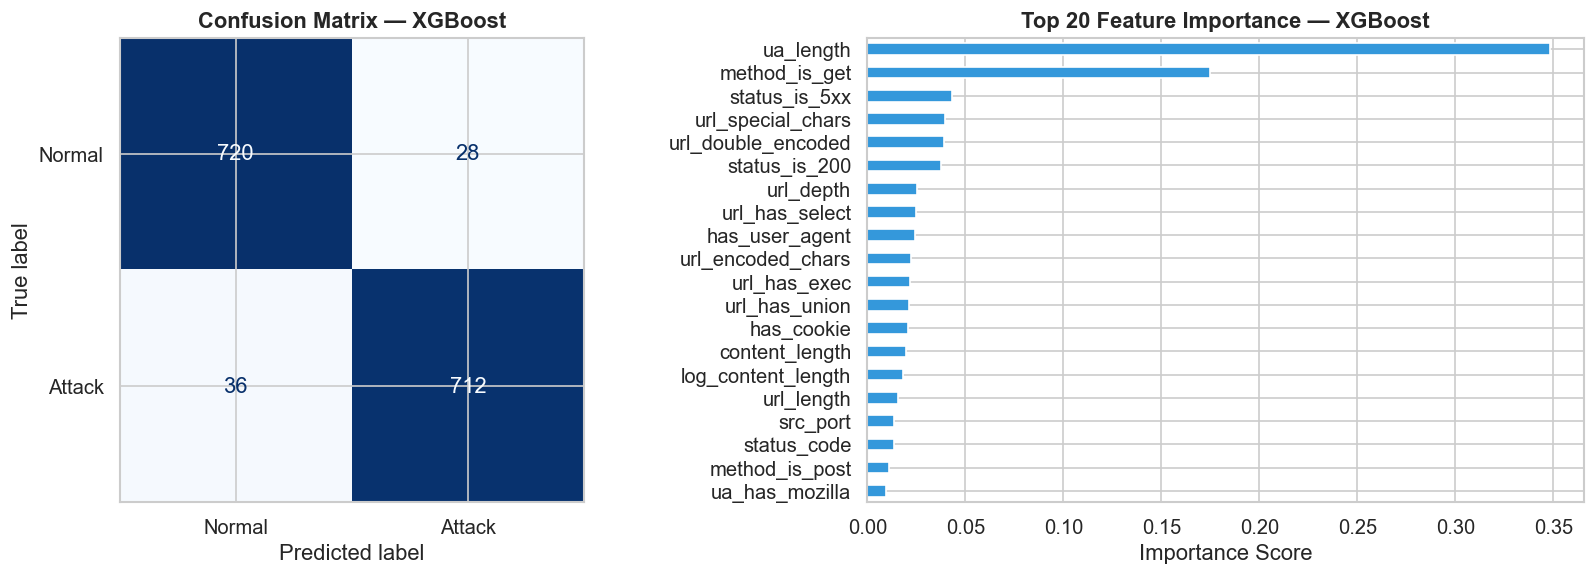


📋 Báo cáo phân loại chi tiết (XGBoost):
              precision    recall  f1-score   support

      Normal       0.95      0.96      0.96       748
      Attack       0.96      0.95      0.96       748

    accuracy                           0.96      1496
   macro avg       0.96      0.96      0.96      1496
weighted avg       0.96      0.96      0.96      1496



In [8]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🏆 PHÂN TÍCH MÔ HÌNH TỐT NHẤT (THEO F1-SCORE)
# ═══════════════════════════════════════════════════════════════════════════════

# --------------------------
# Chọn mô hình tốt nhất
# --------------------------
# Tiêu chí: F1-score (cân bằng giữa Precision và Recall)
best_binary = max(binary_results, key=lambda x: binary_results[x]["f1"])

print(f"🏆 Mô hình tốt nhất (F1): {best_binary}")


# ═══════════════════════════════════════════════════════════════════════════════
# 📊 VISUALIZATION: CONFUSION MATRIX + FEATURE IMPORTANCE
# ═══════════════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# ───────────────────────────────────────────────────────────────────────────────
# 📉 1. CONFUSION MATRIX
# ───────────────────────────────────────────────────────────────────────────────

# Ma trận nhầm lẫn giữa:
# - Normal (0)
# - Attack (1)
cm = confusion_matrix(y_bin_val, binary_results[best_binary]["y_pred"])

disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"])

# Vẽ confusion matrix
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title(f"Confusion Matrix — {best_binary}", fontweight="bold")


# ───────────────────────────────────────────────────────────────────────────────
# 📊 2. FEATURE IMPORTANCE (NẾU MODEL HỖ TRỢ)
# ───────────────────────────────────────────────────────────────────────────────

# Lấy model tốt nhất
best_model = binary_results[best_binary]["model"]

# Chỉ một số model tree-based có feature_importances_
if hasattr(best_model, "feature_importances_"):

    # Tạo Series: feature → importance score
    imp = pd.Series(best_model.feature_importances_, index=X.columns)

    # Lấy 20 feature quan trọng nhất
    top20 = imp.nlargest(20)

    # Sắp xếp tăng dần để vẽ horizontal bar chart đẹp hơn
    top20.sort_values().plot(
        kind="barh", ax=axes[1], color="#3498db", edgecolor="white"
    )

    axes[1].set_title(f"Top 20 Feature Importance — {best_binary}", fontweight="bold")

    axes[1].set_xlabel("Importance Score")


# ═══════════════════════════════════════════════════════════════════════════════
# 🎯 FINAL RENDER
# ═══════════════════════════════════════════════════════════════════════════════

plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# 📋 CLASSIFICATION REPORT (CHI TIẾT)
# ═══════════════════════════════════════════════════════════════════════════════

print(f"\n📋 Báo cáo phân loại chi tiết ({best_binary}):")

print(
    classification_report(
        y_bin_val,
        binary_results[best_binary]["y_pred"],
        target_names=["Normal", "Attack"],
    )
)

In [9]:
# ─── Đánh giá trên Test Set (mô hình tốt nhất) ─────────────────────────────
best_model = binary_results[best_binary]['model']
X_te = X_test_s if 'Logistic' in best_binary else X_test

y_test_pred = best_model.predict(X_te)
y_test_prob = best_model.predict_proba(X_te)[:, 1]

print(f'🧪 KẾT QUẢ CUỐI CÙNG TRÊN TEST SET — {best_binary}:')
print(f'   Accuracy  : {accuracy_score(y_bin_test, y_test_pred):.4f}')
print(f'   Precision : {precision_score(y_bin_test, y_test_pred):.4f}')
print(f'   Recall    : {recall_score(y_bin_test, y_test_pred):.4f}')
print(f'   F1-Score  : {f1_score(y_bin_test, y_test_pred):.4f}')
print(f'   ROC-AUC   : {roc_auc_score(y_bin_test, y_test_prob):.4f}')
print()
print(classification_report(y_bin_test, y_test_pred, target_names=['Normal','Attack']))

🧪 KẾT QUẢ CUỐI CÙNG TRÊN TEST SET — XGBoost:
   Accuracy  : 0.9660
   Precision : 0.9679
   Recall    : 0.9640
   F1-Score  : 0.9659
   ROC-AUC   : 0.9969

              precision    recall  f1-score   support

      Normal       0.96      0.97      0.97       750
      Attack       0.97      0.96      0.97       750

    accuracy                           0.97      1500
   macro avg       0.97      0.97      0.97      1500
weighted avg       0.97      0.97      0.97      1500

